# Ну, для начала импортируем нужные библиотеки и попробуем зафиксировать сид для воспроизводимости результатов


In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
import random 

SEED = 21
random.seed(SEED)
np.random.seed(SEED)


# Импорт Датасета. 60000 объектов и меток для обучения и еще 10000 для тестов. Преобразование данных объектов в двумерный массив и преобразование меток в вектора вида [0，0，0，1，0....].

In [40]:
import gzip

with gzip.open("data/train-images-idx3-ubyte.gz", "rb") as f:
    header = f.read(16)
    magic = np.frombuffer(header[0:4], dtype=">u4")[0]
    quantity = np.frombuffer(header[4:8], dtype=">u4")[0]
    height = np.frombuffer(header[8:12], dtype=">u4")[0]
    width = np.frombuffer(header[12:16], dtype=">u4")[0]
    print('Train massive Q =',quantity,'H =', height,'W =',
    width)

    big_buf = f.read()
    images_train = np.frombuffer(big_buf, dtype=np.uint8).reshape(quantity, height,
    width)

with gzip.open("data/train-labels-idx1-ubyte.gz", "rb") as f:
    header = f.read(8)
    labels_buf = f.read()
    labels_train = np.frombuffer(labels_buf, dtype="uint8")
    print (labels_train [:10])

with gzip.open("data/t10k-images-idx3-ubyte.gz", "rb") as f:
    header = f.read(16)
    magic = np.frombuffer(header[0:4], dtype=">u4")[0]
    quantity = np.frombuffer(header[4:8], dtype=">u4")[0]
    height = np.frombuffer(header[8:12], dtype=">u4")[0]
    width = np.frombuffer(header[12:16], dtype=">u4")[0]
    print('Test massive Q =',quantity,'H =', height,'W =',
    width)

    big_buf = f.read()
    images_test = np.frombuffer(big_buf, dtype=np.uint8).reshape(quantity, height,
    width)

with gzip.open("data/t10k-labels-idx1-ubyte.gz", "rb") as f:
    header = f.read(8)
    labels_buf = f.read()
    labels_test = np.frombuffer(labels_buf, dtype="uint8")
    print (labels_test [:10])

#NORMALIZATION

x_train = images_train.reshape(60000, 784)
x_train = x_train.astype(np.float32) / 255.0

x_test = images_test.reshape(10000, 784)
x_test = x_test.astype(np.float32) / 255.0

def v_vector(labels_any, classes=10):
    result = np.zeros((labels_any.shape[0], classes), dtype = np.float32)
    for i in range (labels_any.shape[0]):
        label = labels_any[i]
        result[i,label] = 1.0
    return result

y_train = v_vector(labels_train, classes = 10)
y_test = v_vector(labels_test, classes = 10)

Train massive Q = 60000 H = 28 W = 28
[9 0 0 3 0 2 7 2 5 5]
Test massive Q = 10000 H = 28 W = 28
[9 2 1 1 6 1 4 6 5 7]


# Определим функции активации и их производные

In [41]:
def sigmoid(z):
    function = 1 / (1+np.exp(-z))
    return function
def sigmoid_deriv(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh(z):
    return np.tanh(z)
def tanh_deriv(z):
    t = np.tanh(z)
    return 1 - t ** 2

def relu(z):
    return np.maximum(0,z)
def relu_deriv(z):
    return (z > 0).astype(z.dtype)

# Функция инициализации весов

In [42]:
def init_w(layers, w_method="xav", cons=0.01, std=0.01, b_method="zeros", rng=None):
    if rng is None:
        rng = np.random
    
    params = []
    for i in range(len(layers)-1):
        layer_in = layers[i]
        layer_out = layers[i+1]

        if w_method == "cons":
            W = np.full((layer_out, layer_in), cons, dtype = np.float32)
        elif w_method == "norm":
            W = rng.randn(layer_out, layer_in).astype(np.float32)*std
        elif w_method == "xav":
            std = (2/(layer_in + layer_out))**0.5
            W = rng.randn(layer_out,layer_in).astype(np.float32)*std
        elif w_method == "kaim":
            std = (2/layer_in)**0.5
            W = rng.randn(layer_out,layer_in).astype(np.float32)*std
        else:
            raise ValueError(f"Unknown w_method: {w_method}")

        if b_method == "zeros":
            b = np.zeros(layer_out, dtype = np.float32)
        elif b_method == "rand":
            b = rng.randn(layer_out).astype(np.float32)*0.01
        else:
            raise ValueError(f"Unknown b_method: {b_method}")
        
        params.append((W, b))
    return params



# Прописываем необходимые функции для расчета градиента при обратном проходе, а именно софтмакс, расчет loss и сам расчет градиента.

In [43]:
def softmax(z):
    z_max = np.max(z, axis=1, keepdims=True)
    z_norm = z - z_max
    P = np.exp(z_norm)/(np.exp(z_norm).sum(axis=1, keepdims=True))
    return P

def calc_loss (P, Y):
    fix_zero = 10**(-10)
    N = P.shape[0]
    log_P = np.log(P + fix_zero)
    obnul = Y*log_P
    loss = -np.sum(obnul)/N
    return loss

def grad_sl (z, Y):
    P = softmax(z)
    N = P.shape[0]
    return (P-Y)/N




# Класс MLP

In [44]:
class SETKA:
    def __init__(self, layers: list[int], activation: str = "sigmoid", weights_method: str = "cons", b_init: str | None = "zeros",
                  dtype=np.float32, seed: int | None = 21):
        self.layers = layers
        self.act = activation
        self.seed = seed
        self.rng = np.random.RandomState(seed)
        self.params = init_w(layers, w_method=weights_method, cons=0.01, std=0.01, b_method=b_init, rng=self.rng)
        self.gradW = [np.zeros_like(W) for (W,b) in self.params]
        self.gradb = [np.zeros_like(b) for (W,b) in self.params]
        self.cache = []
        
        self.dtype = dtype

    def forward(self, X):

        A = X

        self.cache = []
        for i, (W, b) in enumerate(self.params):

            A_prev = A
            Z = A_prev @ W.T + b

            if i< len(self.params) - 1:
                if self.act == "sigmoid":
                    A = sigmoid(Z)
                elif self.act == "tanh":
                    A = tanh(Z)
                elif self.act == "relu":
                    A = relu(Z)
            else: 
                A = Z

            self.cache.append((A_prev, Z))

        return A
    
    def backward (self, grad_los_out):

        dZ = grad_los_out

        for i in reversed(range(len(self.params))):
            W, b = self.params[i]
            A_prev, Z = self.cache[i]
            self.gradW[i] = dZ.T @ A_prev
            self.gradb[i] = dZ.sum(axis=0)

            if i == 0:
                continue
            elif i > 0:
                dA_prev = dZ @ W
                Z_prev = self.cache[i-1][1]

                if self.act == "sigmoid":
                    dZ = dA_prev * sigmoid_deriv(Z_prev)
                elif self.act == "tanh":
                    dZ = dA_prev * tanh_deriv(Z_prev)
                elif self.act == "relu":
                    dZ = dA_prev * relu_deriv(Z_prev)

    def zero_grad(self):
        self.gradW = [np.zeros_like(W) for (W,b) in self.params]
        self.gradb = [np.zeros_like(b) for (W,b) in self.params]  

    def parametrs(self):
        return self.params

    def predict(self, X):
        logits = self.forward(X)
        return np.argmax(logits, axis=1)


        


# Функция или цикл обучения нейросети. Разделение подборки train на train (50000) и validation (10000).

In [45]:
N_train = 50000

X_tr = x_train[:N_train]      
Y_tr = y_train[:N_train]       
X_val = x_train[N_train:]     
Y_val = y_train[N_train:]     

def train_model(net, x_train, y_train, X_val, Y_val,
                epochs=5, batch_size=32, lr=0.01):
    
    N = x_train.shape[0]
    history = {
        "train_loss": [], "train_acc": [], "train_prec": [], "train_rec": [], "train_f1": [],
        "val_loss":   [], "val_acc":   [], "val_prec":   [], "val_rec":   [], "val_f1":   [],
        "grad_norm":  [],
    }
    
    for epoch in range(epochs):
        indices = np.random.permutation(N)
        X_shuf = x_train[indices]
        Y_shuf = y_train[indices]
        
        epoch_loss = 0.0
        n_batches = 0
        batch_grad_norms = []
        
        # ===== цикл по батчам =====
        for start in range(0, N, batch_size):
            X_batch = X_shuf[start:start + batch_size]
            Y_batch = Y_shuf[start:start + batch_size]
            
            logits = net.forward(X_batch)
            loss = calc_loss(softmax(logits), Y_batch)
            epoch_loss += loss
            n_batches += 1
            
            dL = grad_sl(logits, Y_batch)
            net.backward(dL)
            
            batch_grad_norms.append(grad_norm(net))
            
            for i, (W, b) in enumerate(net.params):
                W -= lr * net.gradW[i]
                b -= lr * net.gradb[i]
            
            net.zero_grad()
                
        # ===== метрики в конце эпохи =====
        train_logits = net.forward(x_train)
        train_acc, train_prec, train_rec, train_f1 = metrics(train_logits, y_train)
        
        val_logits = net.forward(X_val)
        val_loss = calc_loss(softmax(val_logits), Y_val)
        val_acc, val_prec, val_rec, val_f1 = metrics(val_logits, Y_val)
        
        avg_train_loss = epoch_loss / n_batches
        avg_grad_norm = np.mean(batch_grad_norms)
        
        history["train_loss"].append(avg_train_loss)
        history["train_acc"].append(train_acc)
        history["train_prec"].append(train_prec)
        history["train_rec"].append(train_rec)
        history["train_f1"].append(train_f1)
        
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_prec"].append(val_prec)
        history["val_rec"].append(val_rec)
        history["val_f1"].append(val_f1)
        
        history["grad_norm"].append(avg_grad_norm)
        
        print(f"Epoch {epoch+1}/{epochs} | "
              f"train_loss={avg_train_loss:.4f} | train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | "
              f"val_f1={val_f1:.4f} | grad_norm={avg_grad_norm:.4f}")
    
    return history


# Определение функции для записи данных о каждой запущенной конфигурации. Расчет дополнительных метрик

In [46]:
results = []

def record(name, net, history, init, bias_init, batch, lr, epochs, conclusion: str | None = "Empty"):
    results.append({
        "name": name,
        "layers": str(net.layers),
        "activation": net.act,
        "init": init,
        "bias_init": bias_init,
        "batch": batch,
        "lr": lr,
        "epochs": epochs,
        "val_loss": history["val_loss"][-1],
        "val_acc":  history["val_acc"][-1],
        "val_f1":   history["val_f1"][-1],
        "conclusion": conclusion,
    })

def metrics(logits, Y_onehot):
    y_pred = np.argmax(logits, axis=1)
    y_true = np.argmax(Y_onehot, axis=1)
    
    acc  = (y_pred == y_true).mean()
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0)
    
    return acc, prec, rec, f1

def grad_norm(net):
    total = 0.0
    for dW in net.gradW:
        total += np.sum(dW ** 2)
    for db in net.gradb:
        total += np.sum(db ** 2)
    return np.sqrt(total)


# Функция построения графиков (4 Конфигурации)

In [47]:

def plots (history, title = "which net"):
    epochs = []
    for i in range(1, len(history["train_loss"])+1):
        epochs.append(i)

    fig, axes = plt.subplots(2,2, figsize = (20,15))

    axes[0,0].set_title("LOSS")
    axes[0,0].set_xlabel("Epochs")
    axes[0,0].set_ylabel("Loss")
    axes[0,0].plot(epochs, history["train_loss"],label="TRAIN", lw=2, marker = "o")
    axes[0,0].plot(epochs, history["val_loss"], label="VALIDATION", lw=2, marker = "o")
    axes[0,0].set_xticks(epochs)
    axes[0,0].legend()
    axes[0,0].grid(True, alpha = 0.3)

    axes[0,1].set_title("ACCURACY")
    axes[0,1].set_xlabel("Epochs")
    axes[0,1].set_ylabel("Accuracy")
    axes[0,1].plot(epochs, history["train_acc"],label="TRAIN", lw=2, marker = "o")
    axes[0,1].plot(epochs, history["val_acc"], label="VALIDATION", lw=2, marker = "o")
    axes[0,1].set_xticks(epochs)
    axes[0,1].legend()
    axes[0,1].grid(True, alpha = 0.3)

    axes[1,0].set_title("F1")
    axes[1,0].set_xlabel("Epochs")
    axes[1,0].set_ylabel("F1")
    axes[1,0].plot(epochs, history["train_f1"],label="TRAIN", lw=2, marker = "o")
    axes[1,0].plot(epochs, history["val_f1"], label="VALIDATION", lw=2, marker = "o")
    axes[1,0].set_xticks(epochs)
    axes[1,0].legend()
    axes[1,0].grid(True, alpha = 0.3)

    axes[1,1].set_title("GRADIENT NORM")
    axes[1,1].set_xlabel("Epochs")
    axes[1,1].set_ylabel("L2 norm")
    axes[1,1].plot(epochs, history["grad_norm"], lw=2, marker = "o")
    axes[1,1].set_xticks(epochs)
    axes[1,1].legend()
    axes[1,1].grid(True, alpha = 0.3)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    
    plt.show()

# Запуск 4х обязательных конфигураций

In [48]:
np.random.seed(21)
net1 = SETKA([784, 100, 50, 10], activation="sigmoid", weights_method="norm", seed=21)
history1 = train_model(net1, X_tr, Y_tr, X_val, Y_val, epochs=35, batch_size=16, lr=0.1)
record("Config 1", net1, history1, "norm", "zeros", 16, 0.1, 35)



Epoch 1/35 | train_loss=2.0474 | train_acc=0.3967 | val_loss=1.5486 | val_acc=0.3867 | val_f1=0.3155 | grad_norm=0.5486
Epoch 2/35 | train_loss=1.0447 | train_acc=0.6933 | val_loss=0.7850 | val_acc=0.6885 | val_f1=0.6634 | grad_norm=0.6282
Epoch 3/35 | train_loss=0.6674 | train_acc=0.7829 | val_loss=0.5865 | val_acc=0.7785 | val_f1=0.7620 | grad_norm=0.7852
Epoch 4/35 | train_loss=0.5279 | train_acc=0.8195 | val_loss=0.5284 | val_acc=0.8129 | val_f1=0.8116 | grad_norm=0.9384
Epoch 5/35 | train_loss=0.4695 | train_acc=0.8362 | val_loss=0.4788 | val_acc=0.8291 | val_f1=0.8288 | grad_norm=1.0137
Epoch 6/35 | train_loss=0.4353 | train_acc=0.8515 | val_loss=0.4339 | val_acc=0.8422 | val_f1=0.8444 | grad_norm=1.0323
Epoch 7/35 | train_loss=0.4082 | train_acc=0.8281 | val_loss=0.4898 | val_acc=0.8116 | val_f1=0.8108 | grad_norm=1.0347
Epoch 8/35 | train_loss=0.3884 | train_acc=0.8661 | val_loss=0.3977 | val_acc=0.8556 | val_f1=0.8522 | grad_norm=1.0277
Epoch 9/35 | train_loss=0.3734 | train_a

In [49]:
np.random.seed(21)
net2 = SETKA([784, 100, 50, 10], activation="sigmoid", weights_method="norm", seed=21)
history2 = train_model(net2, X_tr, Y_tr, X_val, Y_val, epochs=15, batch_size=32, lr=0.01)
record("Config 2", net2, history2, "norm", "zeros", 32, 0.01, 15)


Epoch 1/15 | train_loss=2.3036 | train_acc=0.0998 | val_loss=2.3047 | val_acc=0.1008 | val_f1=0.0183 | grad_norm=0.6013
Epoch 2/15 | train_loss=2.3033 | train_acc=0.0990 | val_loss=2.3036 | val_acc=0.1050 | val_f1=0.0190 | grad_norm=0.6009
Epoch 3/15 | train_loss=2.3036 | train_acc=0.0995 | val_loss=2.3029 | val_acc=0.1023 | val_f1=0.0186 | grad_norm=0.5985
Epoch 4/15 | train_loss=2.3034 | train_acc=0.1006 | val_loss=2.3032 | val_acc=0.0970 | val_f1=0.0177 | grad_norm=0.6016
Epoch 5/15 | train_loss=2.3034 | train_acc=0.1009 | val_loss=2.3043 | val_acc=0.0955 | val_f1=0.0174 | grad_norm=0.5942
Epoch 6/15 | train_loss=2.3034 | train_acc=0.0996 | val_loss=2.3029 | val_acc=0.1021 | val_f1=0.0185 | grad_norm=0.5870
Epoch 7/15 | train_loss=2.3032 | train_acc=0.0996 | val_loss=2.3032 | val_acc=0.1021 | val_f1=0.0185 | grad_norm=0.5875
Epoch 8/15 | train_loss=2.3030 | train_acc=0.0998 | val_loss=2.3017 | val_acc=0.1008 | val_f1=0.0183 | grad_norm=0.5907
Epoch 9/15 | train_loss=2.3023 | train_a

In [50]:
np.random.seed(21)
net3 = SETKA([784, 392, 196, 98, 10], activation="tanh", weights_method="xav", seed=21)
history3 = train_model(net3, X_tr, Y_tr, X_val, Y_val, epochs=15, batch_size=32, lr=0.01)
record("Config 3", net3, history3, "xav","zeros", 32, 0.01, 15)




Epoch 1/15 | train_loss=0.6464 | train_acc=0.8265 | val_loss=0.4977 | val_acc=0.8207 | val_f1=0.8157 | grad_norm=2.3220
Epoch 2/15 | train_loss=0.4574 | train_acc=0.8323 | val_loss=0.4657 | val_acc=0.8304 | val_f1=0.8270 | grad_norm=2.3559
Epoch 3/15 | train_loss=0.4191 | train_acc=0.8540 | val_loss=0.4237 | val_acc=0.8470 | val_f1=0.8416 | grad_norm=2.3728
Epoch 4/15 | train_loss=0.3982 | train_acc=0.8620 | val_loss=0.4079 | val_acc=0.8521 | val_f1=0.8525 | grad_norm=2.4164
Epoch 5/15 | train_loss=0.3806 | train_acc=0.8654 | val_loss=0.4011 | val_acc=0.8563 | val_f1=0.8571 | grad_norm=2.3994
Epoch 6/15 | train_loss=0.3674 | train_acc=0.8737 | val_loss=0.3785 | val_acc=0.8628 | val_f1=0.8640 | grad_norm=2.3770
Epoch 7/15 | train_loss=0.3568 | train_acc=0.8692 | val_loss=0.3915 | val_acc=0.8548 | val_f1=0.8564 | grad_norm=2.4093
Epoch 8/15 | train_loss=0.3465 | train_acc=0.8774 | val_loss=0.3710 | val_acc=0.8638 | val_f1=0.8607 | grad_norm=2.4034
Epoch 9/15 | train_loss=0.3388 | train_a

In [51]:
np.random.seed(21)
net4 = SETKA([784, 392, 196, 98, 49, 25, 10], activation="relu", weights_method="kaim", seed=21)
history4 = train_model(net4, X_tr, Y_tr, X_val, Y_val, epochs=15, batch_size=64, lr=0.01)
record("Config 4", net4, history4, "kaim", "zeros",64, 0.01, 15)


Epoch 1/15 | train_loss=0.8339 | train_acc=0.8028 | val_loss=0.5542 | val_acc=0.8032 | val_f1=0.7922 | grad_norm=3.7247
Epoch 2/15 | train_loss=0.5096 | train_acc=0.7448 | val_loss=0.7667 | val_acc=0.7473 | val_f1=0.7447 | grad_norm=3.7877
Epoch 3/15 | train_loss=0.4510 | train_acc=0.8501 | val_loss=0.4464 | val_acc=0.8444 | val_f1=0.8400 | grad_norm=3.5800
Epoch 4/15 | train_loss=0.4173 | train_acc=0.8531 | val_loss=0.4468 | val_acc=0.8440 | val_f1=0.8471 | grad_norm=3.4337
Epoch 5/15 | train_loss=0.3907 | train_acc=0.8501 | val_loss=0.4544 | val_acc=0.8421 | val_f1=0.8426 | grad_norm=3.3059
Epoch 6/15 | train_loss=0.3733 | train_acc=0.8651 | val_loss=0.4154 | val_acc=0.8559 | val_f1=0.8549 | grad_norm=3.2729
Epoch 7/15 | train_loss=0.3570 | train_acc=0.8452 | val_loss=0.4564 | val_acc=0.8308 | val_f1=0.8366 | grad_norm=3.2537
Epoch 8/15 | train_loss=0.3420 | train_acc=0.8822 | val_loss=0.3713 | val_acc=0.8683 | val_f1=0.8654 | grad_norm=3.1780
Epoch 9/15 | train_loss=0.3292 | train_a

# Графики к 4м обязательным конфигурациям

C:\Users\NOTSAME\AppData\Local\Temp\ipykernel_17332\3996354065.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1,1].legend()


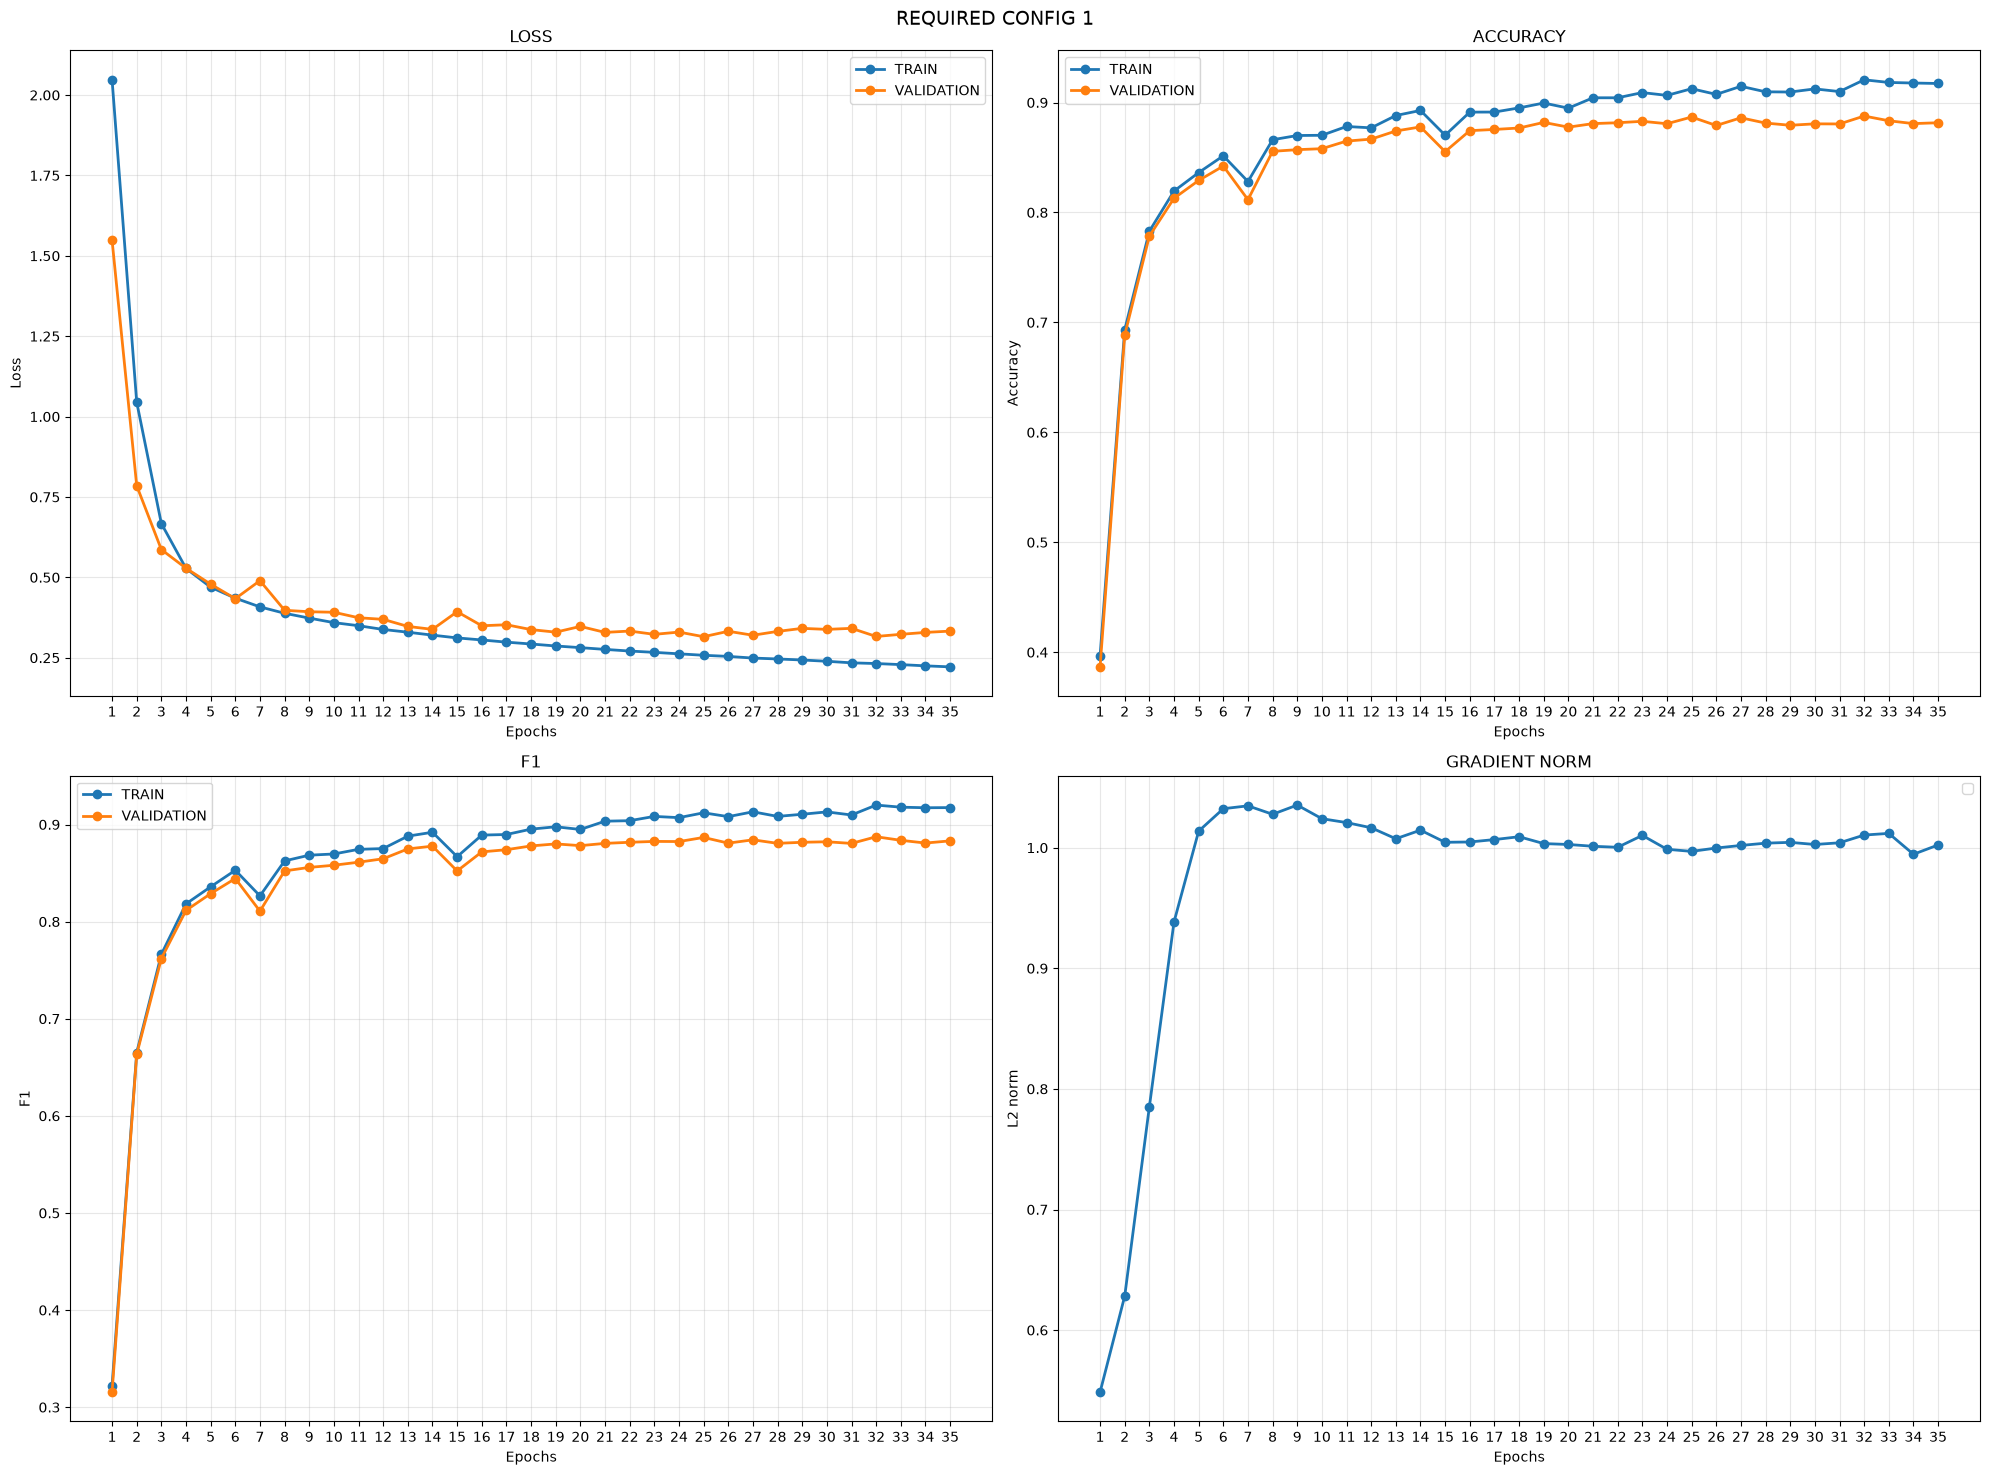

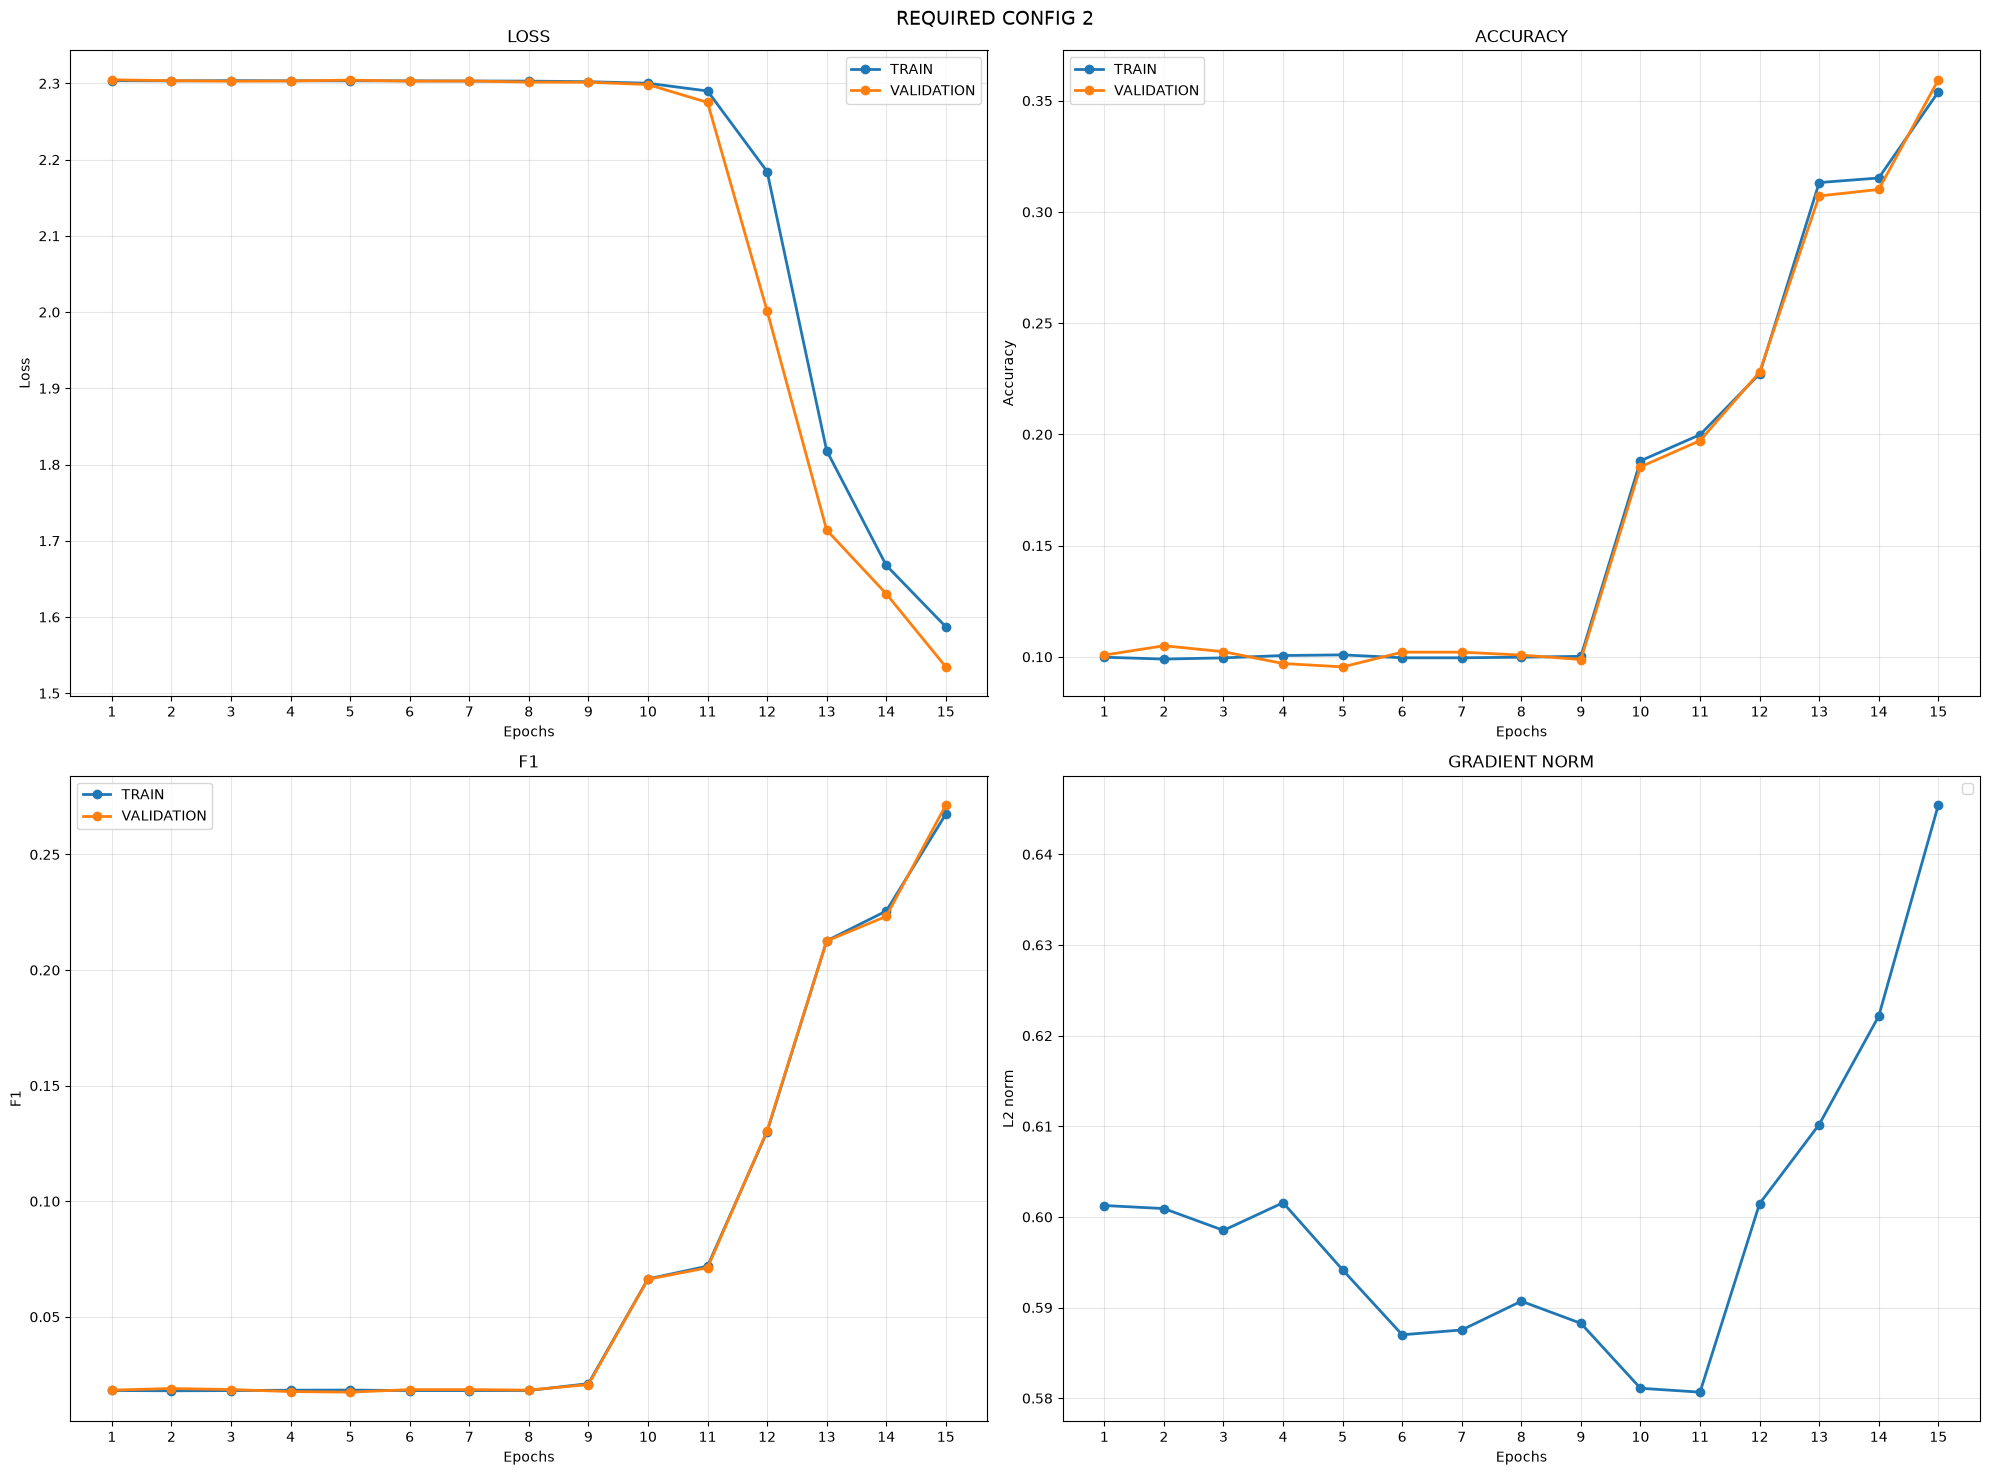

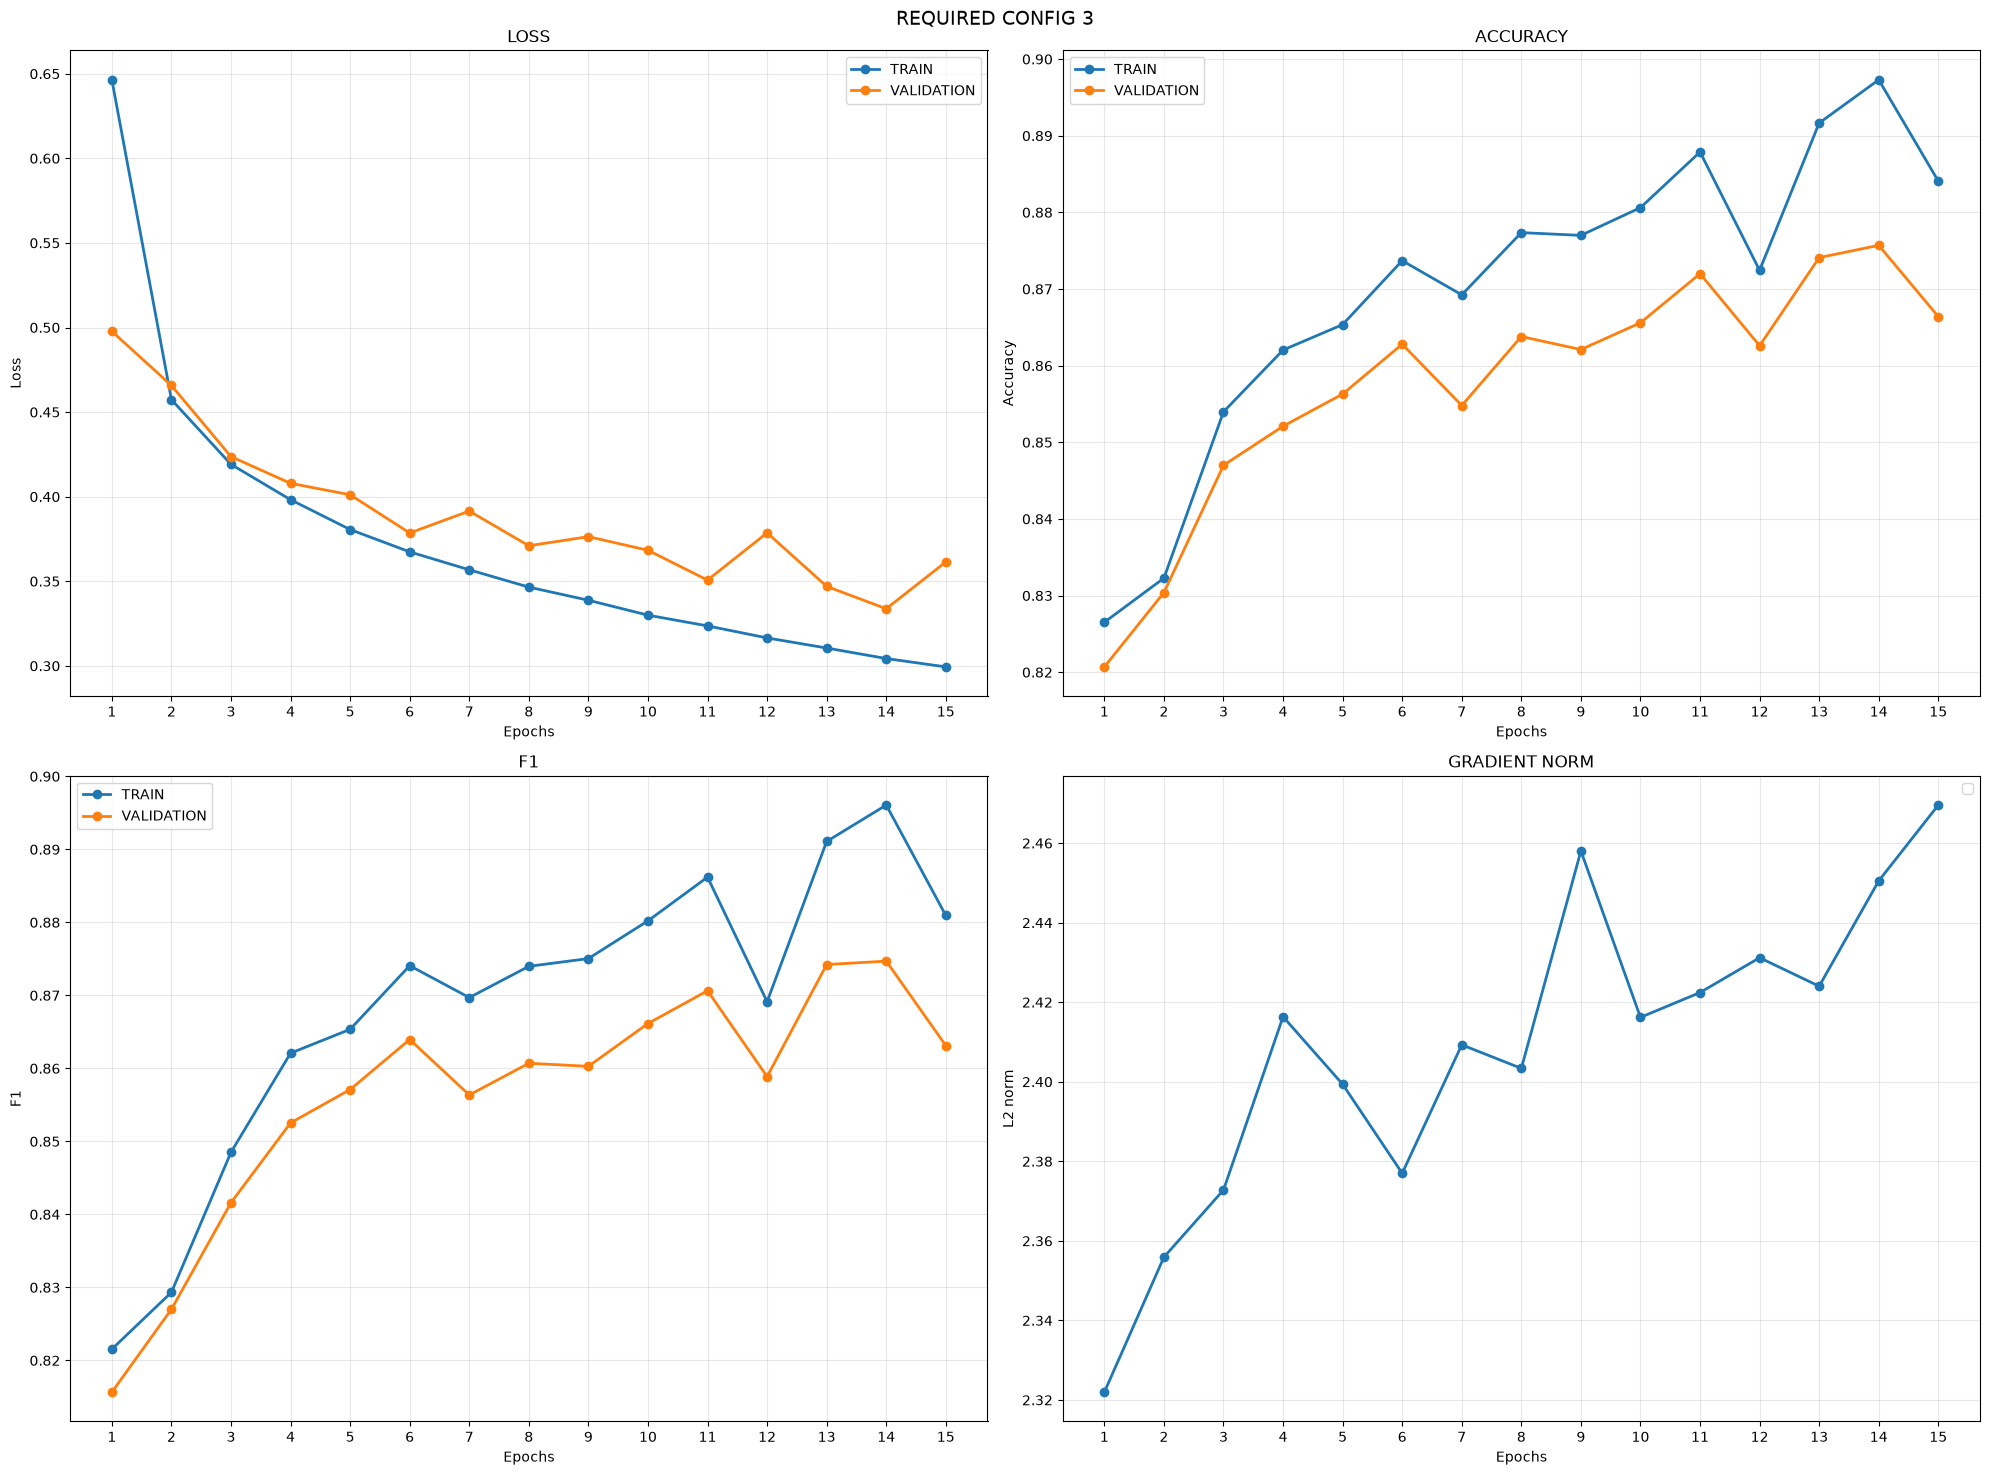

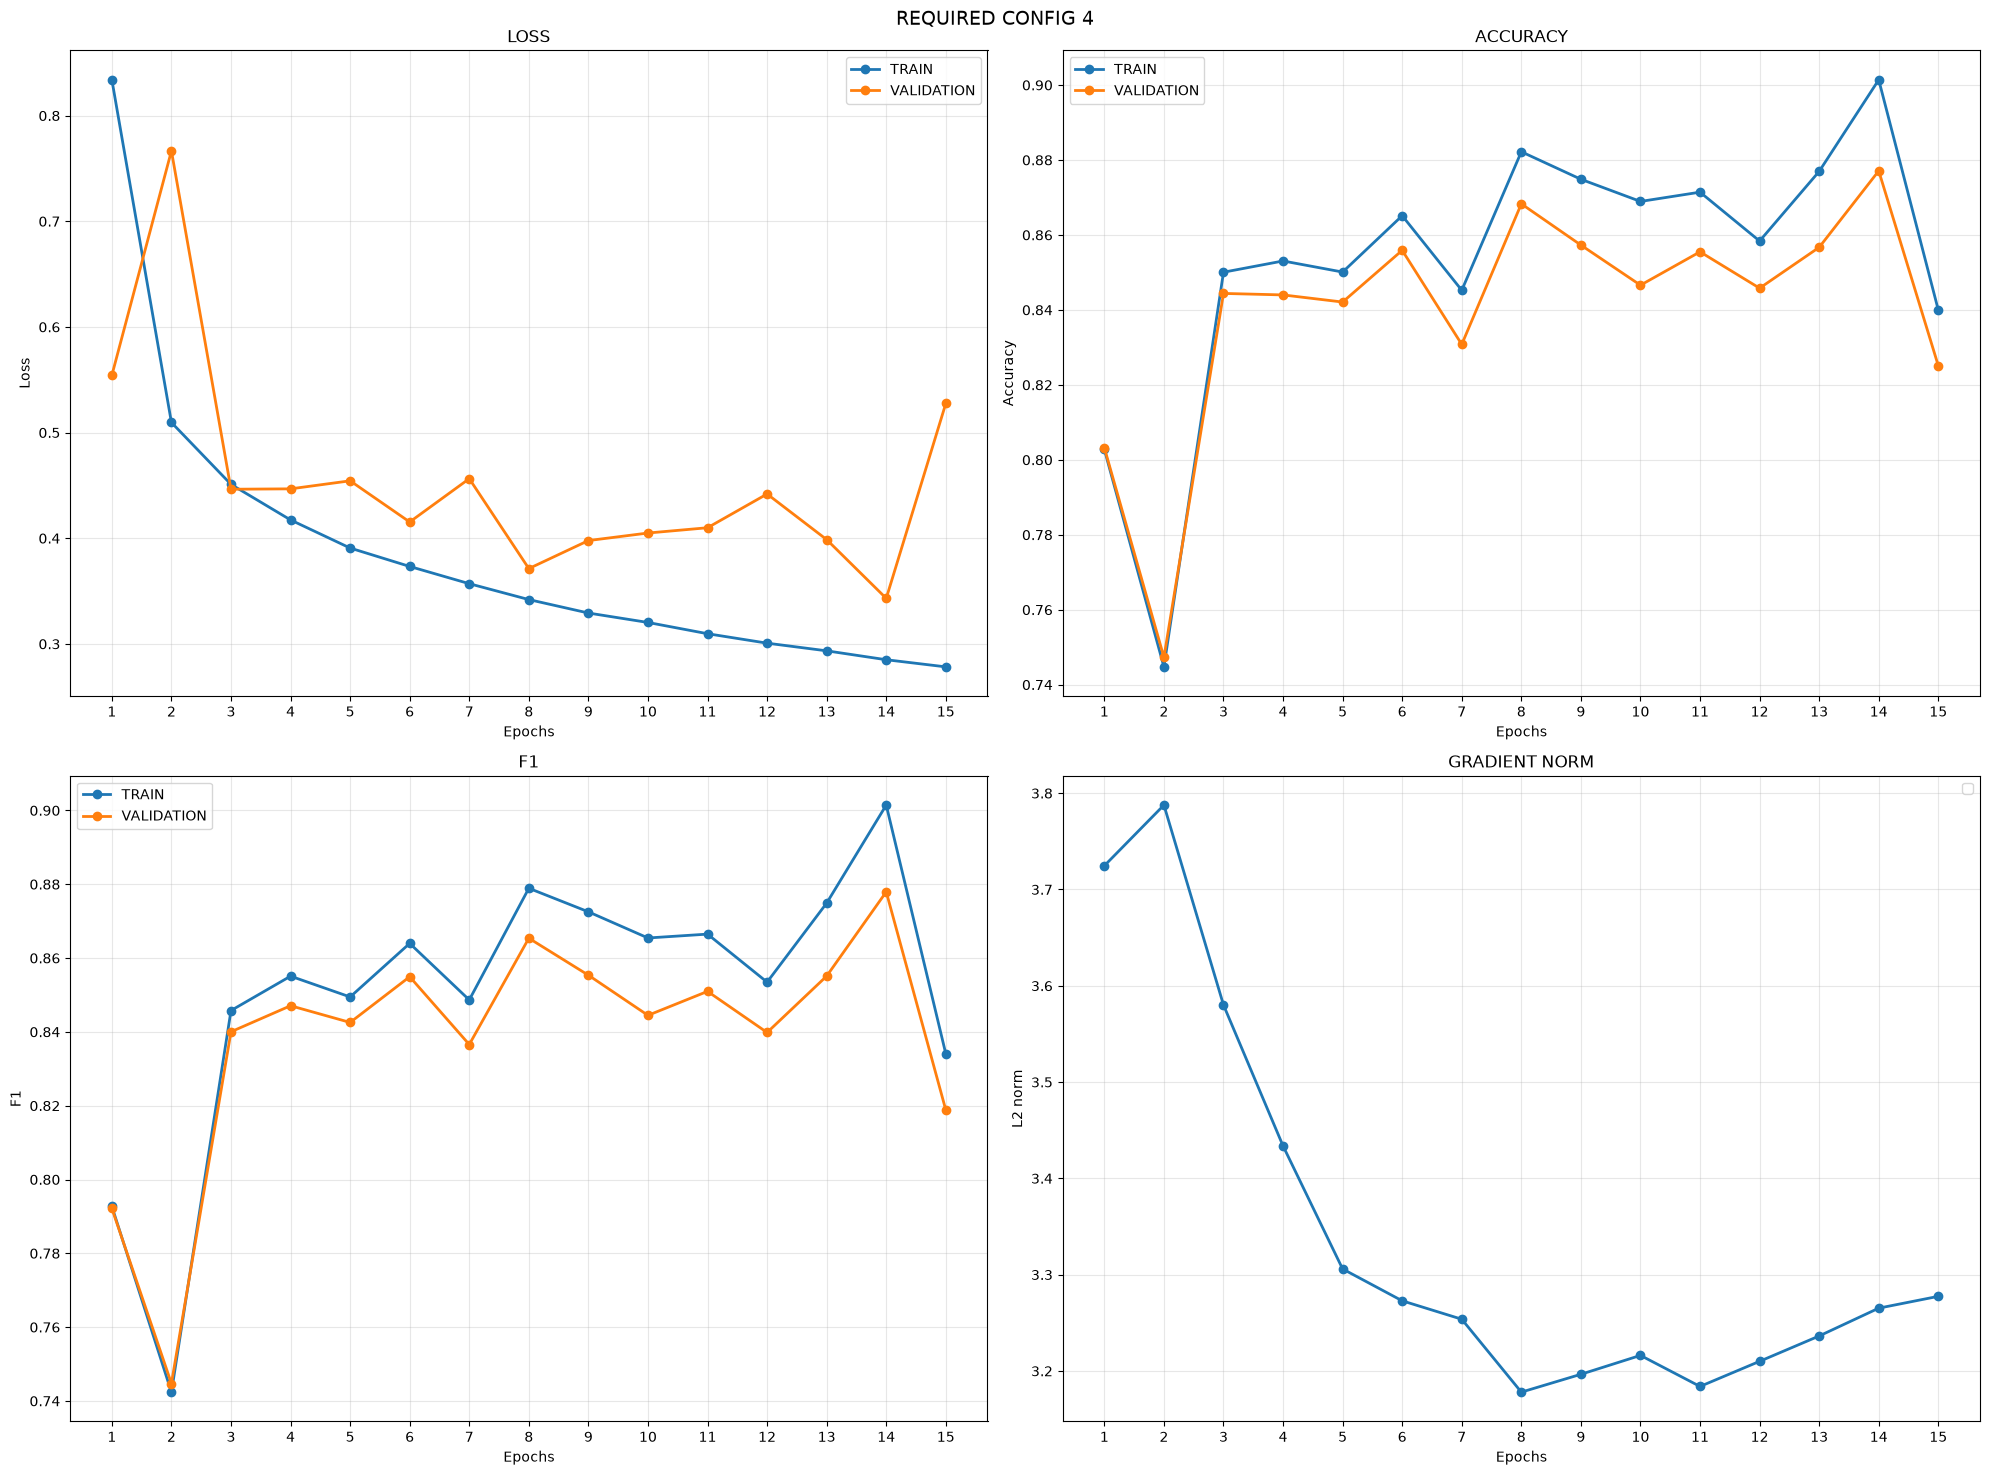

In [52]:
plots(history1, title="REQUIRED CONFIG 1")
plots(history2, title="REQUIRED CONFIG 2")
plots(history3, title="REQUIRED CONFIG 3")
plots(history4, title="REQUIRED CONFIG 4")

# Итоговая таблица по Основным четырем конфигурациям

In [53]:

from IPython.display import Markdown, display

def print_md_table(results):
    headers = ['Эксперимент', 'Архитектура', 'Init', 'Act', 'Bias init',
               'Batch', 'LR', 'Эпохи', 'Val loss', 'Val acc', 'Val F1', 'Вывод']
    keys = ['name', 'layers', 'init', 'activation', 'bias_init',
            'batch', 'lr', 'epochs', 'val_loss', 'val_acc', 'val_f1', 'conclusion']

    lines = ['| ' + ' | '.join(headers) + ' |',
             '|' + '|'.join(['---'] * len(headers)) + '|']

    for r in results:
        row = []
        for k in keys:
            v = r[k]
            if isinstance(v, float):
                v = f'{v:.4f}'
            row.append(str(v))
        lines.append('| ' + ' | '.join(row) + ' |')

    display(Markdown('\n'.join(lines)))

print_md_table(results)

| Эксперимент | Архитектура | Init | Act | Bias init | Batch | LR | Эпохи | Val loss | Val acc | Val F1 | Вывод |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Config 1 | [784, 100, 50, 10] | norm | sigmoid | zeros | 16 | 0.1000 | 35 | 0.33289963 | 0.8816 | 0.8832 | Empty |
| Config 2 | [784, 100, 50, 10] | norm | sigmoid | zeros | 32 | 0.0100 | 15 | 1.5345899 | 0.3594 | 0.2714 | Empty |
| Config 3 | [784, 392, 196, 98, 10] | xav | tanh | zeros | 32 | 0.0100 | 15 | 0.36142105 | 0.8664 | 0.8631 | Empty |
| Config 4 | [784, 392, 196, 98, 49, 25, 10] | kaim | relu | zeros | 64 | 0.0100 | 15 | 0.5275707 | 0.8251 | 0.8188 | Empty |

# Выводы по конфигурациям:

### Конфигурация 1

Loss падает плавно с 2.3 до 0.33 за 35 эпох.
Accuracy и F1 растут синхронно и стабильно.
Train и val почти совпадают — переобучения нет.
Норма градиента стабилизируется на ~1.0 после 5-й эпохи.

#### Вывод

Лучший результат из четырёх. 35 эпох с lr=0.1 позволили sigmoid полностью «разогреться». Стабильное обучение, без переобучения.

### Конфигурация 2

Loss стоит на 2.3 девять эпох — сеть вообще не учится.
Только на 10–15-й эпохах начинает двигаться.
К концу обучения val_acc = 0.36, val_f1 = 0.27.
Норма градиента сначала падает (0.60 → 0.58), потом растёт (до 0.64) — сеть только-только «просыпается».

#### Вывод

Маленький lr=0.01 не пробивает стартовое плато sigmoid. Той же архитектуре, что в Config 1, не хватило ни шага обучения, ни эпох.

### Конфигурация 3

Loss падает с 0.65 до 0.36 быстро и стабильно.
Accuracy растёт до 0.87, F1 до 0.86.
Колебания по эпохам есть, но небольшие.
Норма градиента растёт с 2.3 до 2.47 — грaдиент не затухает, tanh справляется.

#### Вывод для таблицы:

Tanh + Xavier на глубокой сети (3 скрытых слоя) отработали отлично. Даже с 15 эпохами и lr=0.01 результат близок к Config 1. Xavier правильно подобрал масштаб под tanh.

### Конфигурация 4

Loss падает с 0.83 до 0.28, но val_loss колеблется сильно.
Accuracy выходит на 0.82–0.83, F1 до 0.88 на train, но val отстаёт.
Виден разрыв между train и val — train_acc 0.90, val_acc 0.83. Это переобучение.
Норма градиента падает с 3.7 до 3.2 — сигнал проходит, но затухает.

#### Вывод

Самая глубокая сеть (5 скрытых слоёв) с ReLU + Kaiming. Учится, но за 15 эпох не успевает дожать. Разрыв train/val намекает на переобучение — возможно, стоит уменьшить архитектуру или добавить эпох.

## Общий вывод:

Глубина + правильная инициализация важнее активации. Конфигурация 3 (tanh + Xavier, 3 слоя) обошёл Конфигурацию 4 (ReLU + Kaiming, 5 слоёв) на тех же эпохах. Kaiming сработал, но 5 слоёв — это много для 15 эпох.

lr=0.1 и 35 эпох «вытянули» sigmoid. Конфигурация 1 — доказательство, что sigmoid может работать, если дать ему время. Конфигурация 2 — доказательство, что с маленьким lr и 15 эпохами он мёртв.

Batch size не главное. Конфигурация 1 с batch=16 победил, Конфигурация 3 с batch=32 близок, но все-таки имеет немного худшие показатели.

Норма градиента — полезная метрика. В Конфигурация 2 она почти не менялась — сеть не училась. В Конфигурация 1 и 3 она росла и стабилизировалась — обучение шло.

# Проверка Гипотезы №4

#### Формулировка
Если веса инициализированы корректно, нулевая инициализация смещений не препятствует успешному обучению сети и не должна существенно ухудшать результат по сравнению со случайной инициализацией смещений.

#### Ожидание

Есть предполодение, что скорее всего эффект оказываться будет, но не критичный. Большой раницы в обучении не будет т.к. При корректировке и пересчете смещений мы не отталкиваемся от изначальных значений смещений.



Epoch 1/15 | train_loss=0.6802 | train_acc=0.8240 | val_loss=0.5175 | val_acc=0.8169 | val_f1=0.8101 | grad_norm=2.0699
Epoch 2/15 | train_loss=0.4745 | train_acc=0.8374 | val_loss=0.4656 | val_acc=0.8295 | val_f1=0.8253 | grad_norm=2.0215
Epoch 3/15 | train_loss=0.4342 | train_acc=0.8510 | val_loss=0.4340 | val_acc=0.8432 | val_f1=0.8382 | grad_norm=2.0500
Epoch 4/15 | train_loss=0.4124 | train_acc=0.8593 | val_loss=0.4169 | val_acc=0.8479 | val_f1=0.8479 | grad_norm=2.0924
Epoch 5/15 | train_loss=0.3947 | train_acc=0.8628 | val_loss=0.4055 | val_acc=0.8539 | val_f1=0.8544 | grad_norm=2.0840
Epoch 6/15 | train_loss=0.3814 | train_acc=0.8691 | val_loss=0.3898 | val_acc=0.8597 | val_f1=0.8608 | grad_norm=2.0651
Epoch 7/15 | train_loss=0.3707 | train_acc=0.8675 | val_loss=0.3942 | val_acc=0.8546 | val_f1=0.8562 | grad_norm=2.0880
Epoch 8/15 | train_loss=0.3606 | train_acc=0.8744 | val_loss=0.3770 | val_acc=0.8624 | val_f1=0.8599 | grad_norm=2.0810
Epoch 9/15 | train_loss=0.3531 | train_a

C:\Users\NOTSAME\AppData\Local\Temp\ipykernel_17332\3996354065.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1,1].legend()


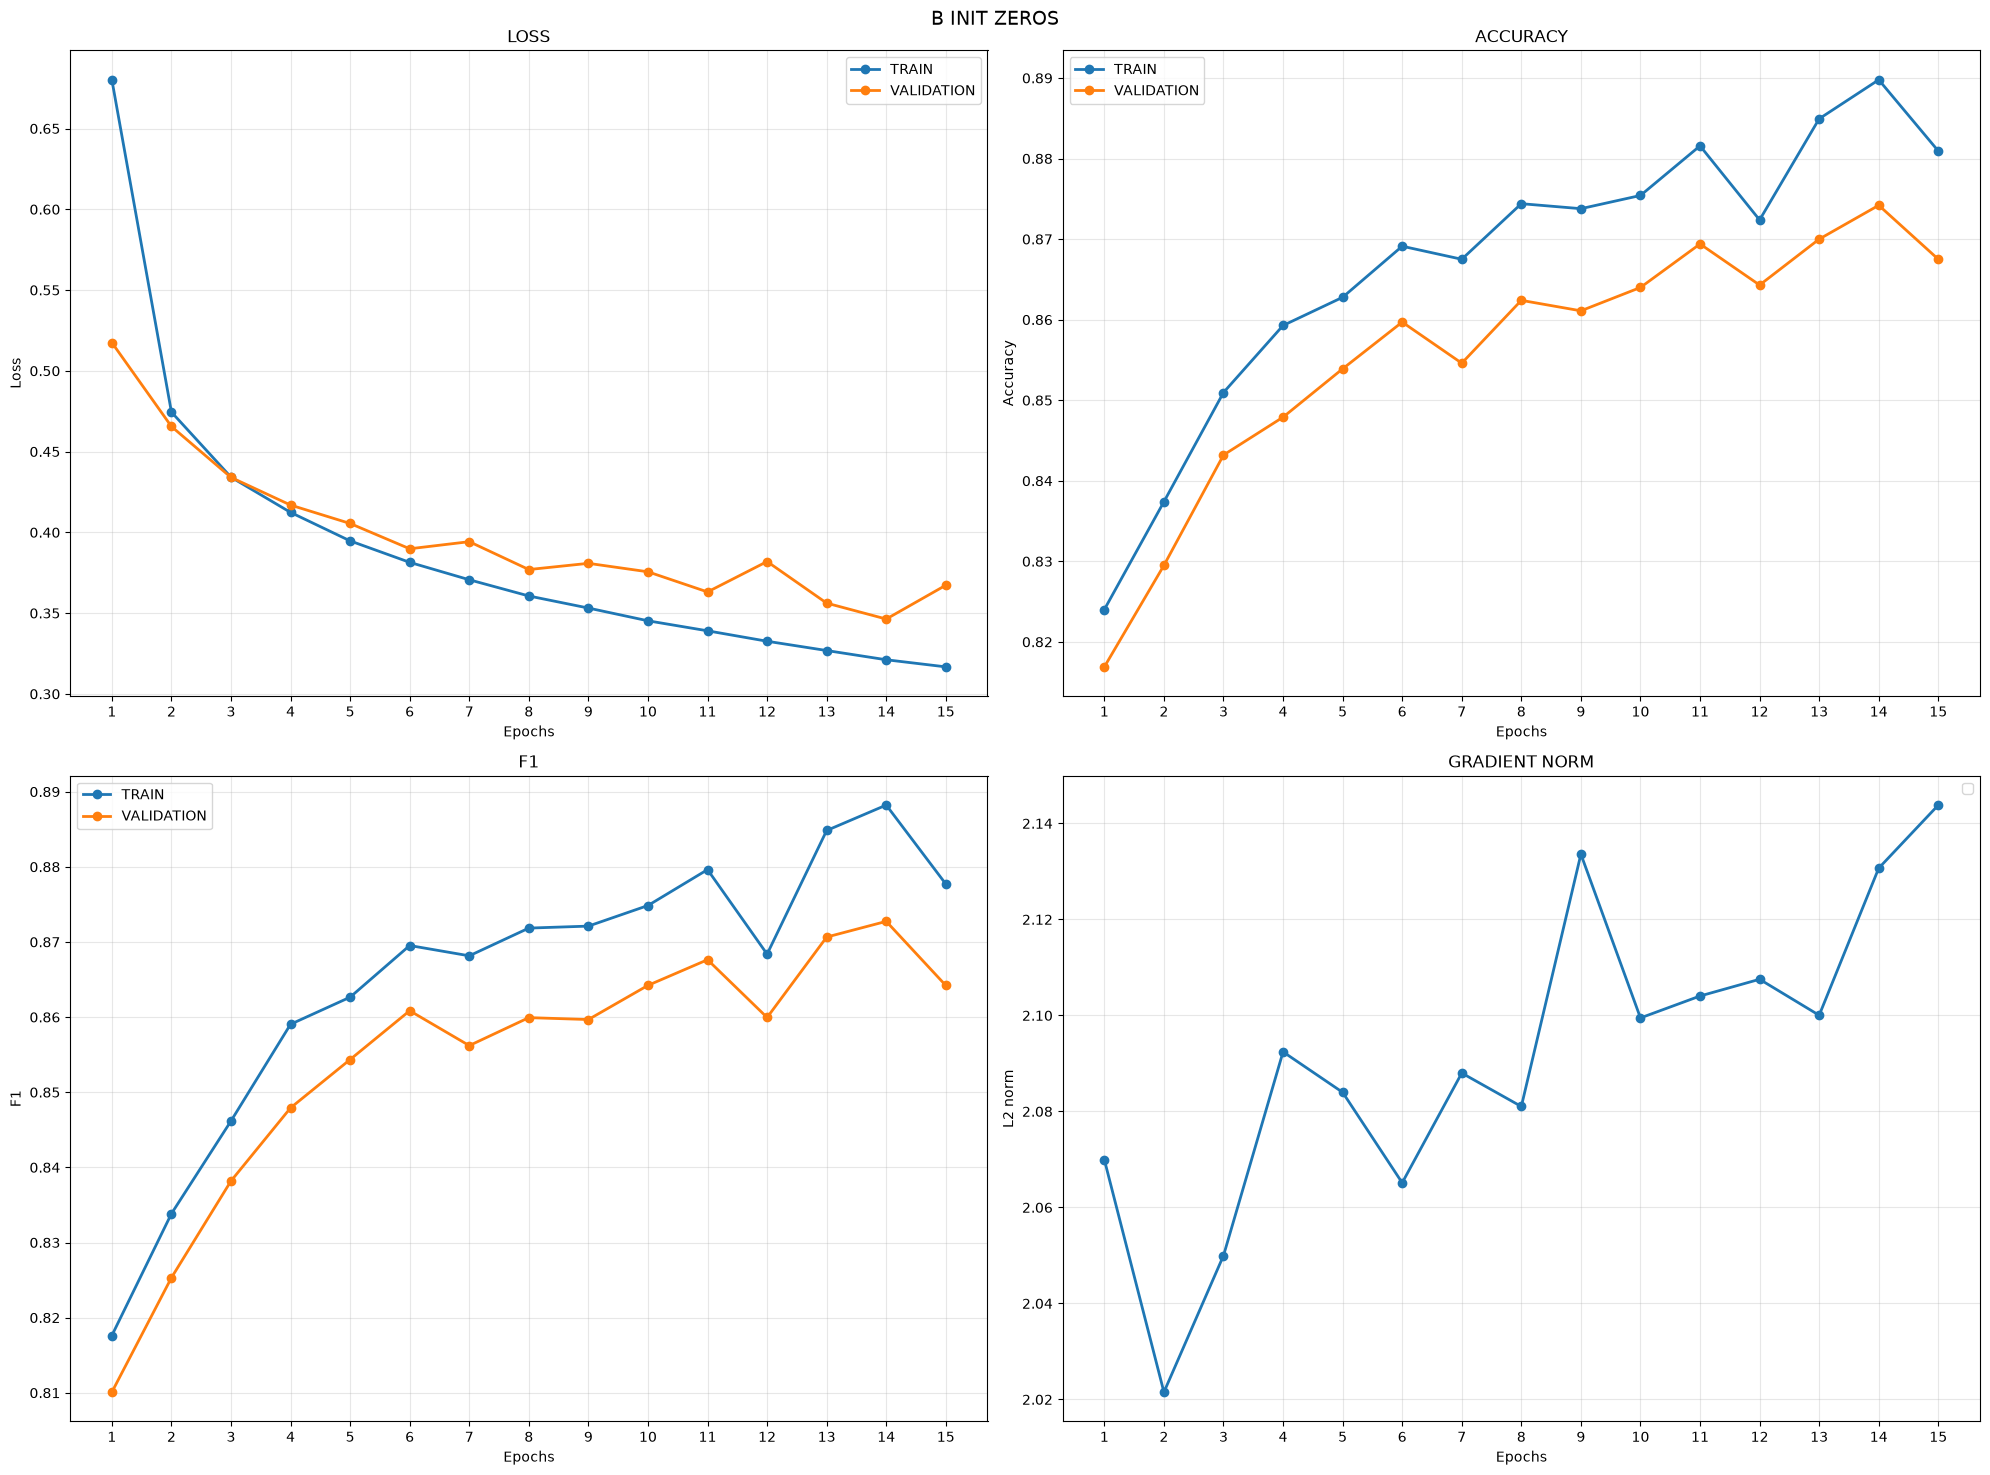

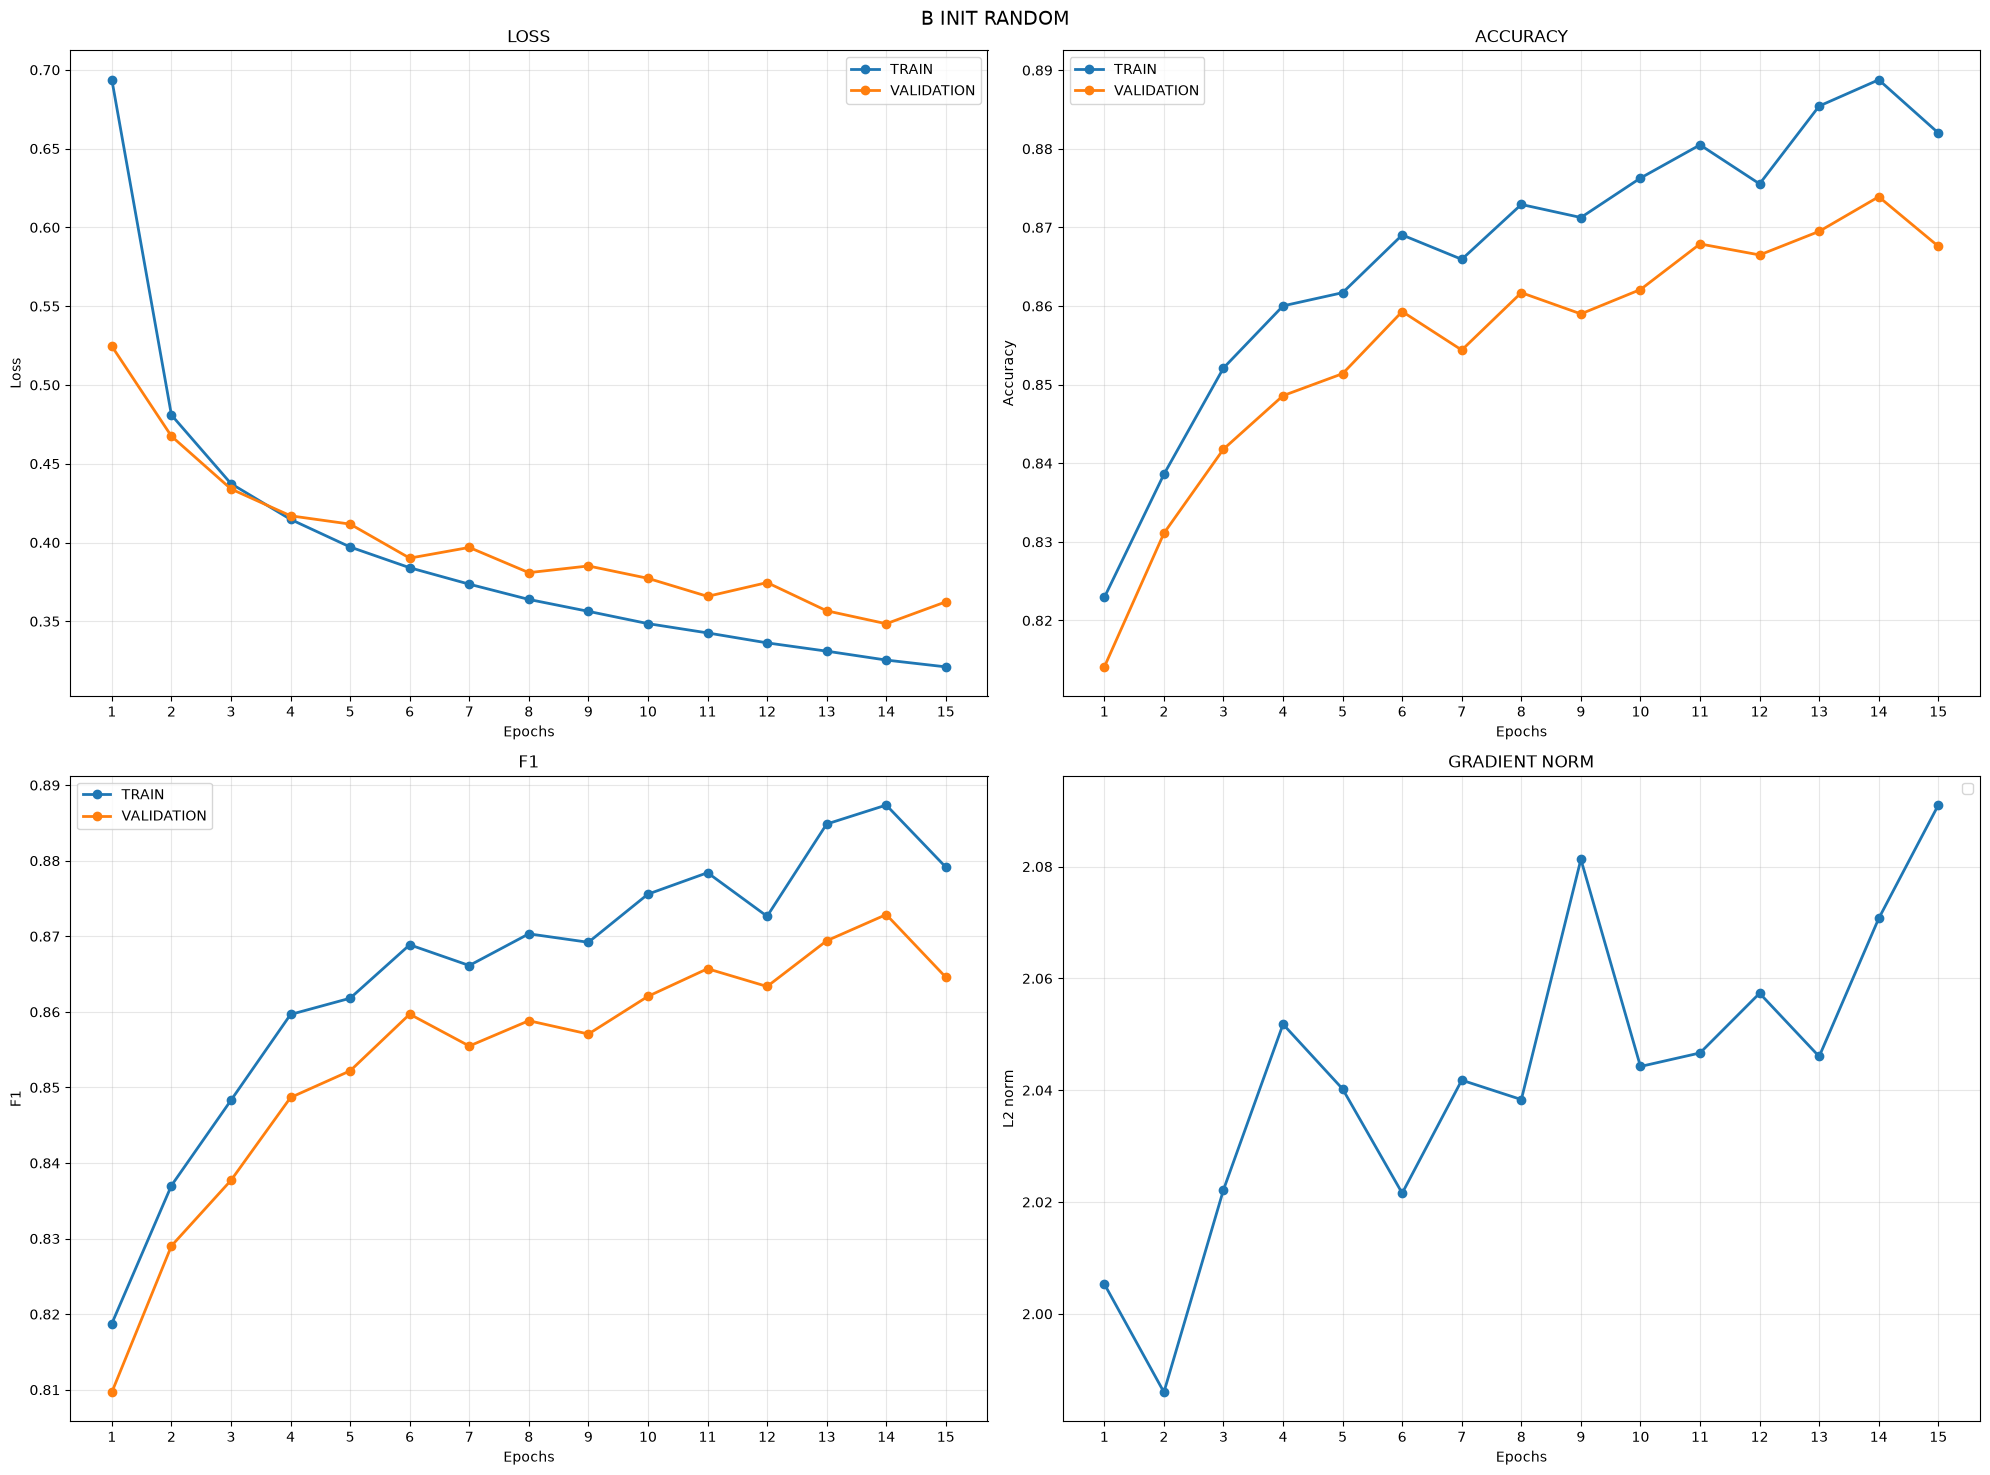

| Эксперимент | Архитектура | Init | Act | Bias init | Batch | LR | Эпохи | Val loss | Val acc | Val F1 | Вывод |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Hypotyse 4 (zeros) | [784, 350, 75, 10] | xav | tanh | zeros | 32 | 0.0100 | 15 | 0.36726996 | 0.8675 | 0.8642 | Empty |
| Hypotyse 4 (zeros) | [784, 350, 75, 10] | xav | tanh | zeros | 32 | 0.0100 | 15 | 0.36726996 | 0.8675 | 0.8642 | Empty |
| Hypotyse 4 (random) | [784, 350, 75, 10] | xav | tanh | rand | 32 | 0.0100 | 15 | 0.3623512 | 0.8676 | 0.8646 | Empty |
| Hypotyse 4 (zeros) | [784, 350, 75, 10] | xav | tanh | zeros | 32 | 0.0100 | 15 | 0.36726996 | 0.8675 | 0.8642 | Empty |
| Hypotyse 4 (random) | [784, 350, 75, 10] | xav | tanh | rand | 32 | 0.0100 | 15 | 0.3623512 | 0.8676 | 0.8646 | Empty |

In [58]:
np.random.seed(21)
net_h4_1 = SETKA([784, 350, 75, 10], activation="tanh", weights_method="xav", seed=21)
history_h4_1 = train_model(net_h4_1, X_tr, Y_tr, X_val, Y_val, epochs=15, batch_size=32, lr=0.01)
record("Hypotyse 4 (zeros)", net_h4_1, history_h4_1, "xav","zeros", 32, 0.01, 15)

np.random.seed(21)
net_h4_2 = SETKA([784, 350, 75, 10], activation="tanh", weights_method="xav",b_init = "rand", seed=21)
history_h4_2 = train_model(net_h4_2, X_tr, Y_tr, X_val, Y_val, epochs=15, batch_size=32, lr=0.01)
record("Hypotyse 4 (random)", net_h4_2, history_h4_2, "xav","rand", 32, 0.01, 15)

plots (history_h4_1, title = "B INIT ZEROS")
plots (history_h4_2, title = "B INIT RANDOM")

hyp4_rows = [r for r in results if "Hypotyse 4" in r["name"]]
print_md_table(hyp4_rows)



## Гипотеза 4 подтверждается.

При корректной инициализации весов (Xavier для tanh в нашем случае) нулевая инициализация смещений не ухудшает обучение. Разница в val accuracy — 0.0001, в val F1 — 0.0004. Это статистический шум, а не эффект. Смещения b=0 обучаются нормально, потому что их градиент db = dZ.sum(axis=0) не зависит от текущего значения b — важно только, что веса ненулевые.